In [1]:
import pandas as pd
import numpy as np
import os

os.makedirs("EDAs", exist_ok=True)


In [2]:
df = pd.read_csv("DatasetML.csv")


In [3]:
df.head()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,7/3/2015
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,7/1/2015
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,4/30/2015
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,6/23/2015
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,4/2/2015


In [4]:
print(df.shape[0])

79330


In [5]:
df=df.drop_duplicates()

In [6]:
print(df.shape[0])

53428


In [7]:
cols = ["LeadTime", "StaysInWeekendNights", "StaysInWeekNights", "ADR"]

outlier = pd.Series(False, index=df.index)

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    is_out = (df[col] < lower_bound) | (df[col] > upper_bound)
    print(f"{col:30s} bounds [{lower_bound:.1f}, {upper_bound:.1f}]  outliers: {is_out.sum():,}")
    outlier |= is_out

before = len(df)                     # save the count BEFORE removing
df = df[~outlier].copy()             # remove outliers
after = len(df)

print(f"\nBefore: {before:,}  After: {after:,}  Removed: {before - after:,} ({(before - after) / before:.1%})")

LeadTime                       bounds [-142.0, 274.0]  outliers: 1,697
StaysInWeekendNights           bounds [-3.0, 5.0]  outliers: 80
StaysInWeekNights              bounds [-2.0, 6.0]  outliers: 687
ADR                            bounds [9.0, 209.0]  outliers: 2,490

Before: 53,428  After: 48,660  Removed: 4,768 (8.9%)


In [8]:
#remove spaces in stringed values
df = df.apply(lambda col: col.map(lambda x: x.strip() if isinstance(x, str) else x))

In [9]:
df = df.replace('NULL', np.nan)
df = df.replace('NA', np.nan)
df = df.replace('', np.nan)

In [10]:
print(df.isna().sum())

IsCanceled                         0
LeadTime                           0
ArrivalDateYear                    0
ArrivalDateMonth                   0
ArrivalDateWeekNumber              0
ArrivalDateDayOfMonth              0
StaysInWeekendNights               0
StaysInWeekNights                  0
Adults                             0
Children                           4
Babies                             0
Meal                               0
Country                            3
MarketSegment                      0
DistributionChannel                0
IsRepeatedGuest                    0
PreviousCancellations              0
PreviousBookingsNotCanceled        0
ReservedRoomType                   0
AssignedRoomType                   0
BookingChanges                     0
DepositType                        0
Agent                           4805
Company                        46221
DaysInWaitingList                  0
CustomerType                       0
ADR                                0
R

In [11]:
#Decision whether having a company matters in column values
group = df["Company"].notna().map({False: "No company", True: "Has company"})
cols = df.select_dtypes(include="number").columns

summary = df[cols].groupby(group).mean().T[["No company", "Has company"]]
summary["Difference"] = summary["Has company"] - summary["No company"]
print(summary.round(2))


Company                      No company  Has company  Difference
IsCanceled                         0.30         0.12       -0.18
LeadTime                          72.78        24.99      -47.80
ArrivalDateYear                 2016.25      2016.19       -0.05
ArrivalDateWeekNumber             26.47        26.82        0.35
ArrivalDateDayOfMonth             15.74        15.69       -0.05
StaysInWeekendNights               0.87         0.47       -0.40
StaysInWeekNights                  2.24         1.45       -0.79
Adults                             1.92         1.18       -0.74
Children                           0.11         0.01       -0.10
Babies                             0.01         0.00       -0.01
IsRepeatedGuest                    0.01         0.39        0.38
PreviousCancellations              0.02         0.24        0.22
PreviousBookingsNotCanceled        0.02         3.11        3.09
BookingChanges                     0.23         0.34        0.12
DaysInWaitingList        

In [12]:
summary = (
    df.groupby(df["Company"].notna())                      
      .agg(Bookings=("LeadTime", "size"),                 
           MedianLeadTime=("LeadTime", "median"),         
           MedianADR=("ADR", "median"))
      .rename(index={False: "No company", True: "Has company"})
)
summary.index.name = None
print(summary)



             Bookings  MedianLeadTime  MedianADR
No company      46221            53.0      107.1
Has company      2439             6.0       80.0


Having a company matters the most in MedianADR and Lead Time; therefore, it will be replaced with a HasCompany boolean instead of dropping it totally off

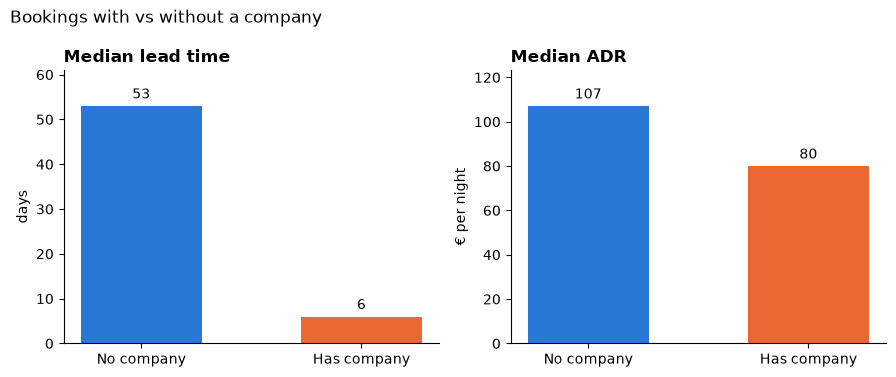

In [13]:
import matplotlib.pyplot as plt

colors = ["#2a78d6", "#eb6834"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))

for ax, col, title, unit in [
    (axes[0], "MedianLeadTime", "Median lead time", "days"),
    (axes[1], "MedianADR", "Median ADR", "€ per night"),
]:
    bars = ax.bar(summary.index, summary[col], color=colors, width=0.55)
    ax.bar_label(bars, fmt="%.0f", padding=3)          # value on top of each bar
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_ylabel(unit)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(0, summary[col].max() * 1.15)          # room for the labels

fig.suptitle("Bookings with vs without a company", x=0.01, ha="left")
plt.tight_layout()
plt.savefig("EDAs/company_leadtime_adr.png", dpi=150)       # for the report
plt.show()

In [14]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

missing_country = df[df["Country"].isna()]
print(len(missing_country))     # 24
print(missing_country)

3
       IsCanceled  LeadTime  ArrivalDateYear ArrivalDateMonth  \
4831            1       193             2015          October   
40770           0         4             2015         November   
61428           0         1             2016         November   

       ArrivalDateWeekNumber  ArrivalDateDayOfMonth  StaysInWeekendNights  \
4831                      42                     15                     0   
40770                     48                     23                     1   
61428                     47                     13                     2   

       StaysInWeekNights  Adults  Children  Babies Meal Country  \
4831                   3       2       0.0       0   BB     NaN   
40770                  2       1       0.0       0   BB     NaN   
61428                  2       2       0.0       0   BB     NaN   

       MarketSegment DistributionChannel  IsRepeatedGuest  \
4831   Offline TA/TO               TA/TO                0   
40770         Groups               TA

In [15]:
no_adults = df["Adults"] == 0
print("Rows with 0 adults:", no_adults.sum())

df = df[~no_adults].copy()
print("Rows left:", len(df))

Rows with 0 adults: 193
Rows left: 48467


In [16]:
df = df.drop(columns=["Country"])


Dropped the rows with no countries (only 3 rows)

In [17]:
df["Children"] = df["Children"].fillna(0).astype(int)


df["HasCompany"] = df["Company"].notna().astype(int)
df = df.drop(columns=["Company"])

df["Agent"] = df["Agent"].fillna(0).astype(str)

C:\Users\kimso\AppData\Local\Temp\ipykernel_2936\1497978468.py:7: Pandas4Warning: 'int' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df["Agent"] = df["Agent"].fillna(0).astype(str)


In [18]:
df["ReservationStatusDate"] = pd.to_datetime(df["ReservationStatusDate"])

In [19]:
df.info()

<class 'pandas.DataFrame'>
Index: 48467 entries, 1 to 79328
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   IsCanceled                   48467 non-null  int64         
 1   LeadTime                     48467 non-null  int64         
 2   ArrivalDateYear              48467 non-null  int64         
 3   ArrivalDateMonth             48467 non-null  str           
 4   ArrivalDateWeekNumber        48467 non-null  int64         
 5   ArrivalDateDayOfMonth        48467 non-null  int64         
 6   StaysInWeekendNights         48467 non-null  int64         
 7   StaysInWeekNights            48467 non-null  int64         
 8   Adults                       48467 non-null  int64         
 9   Children                     48467 non-null  int64         
 10  Babies                       48467 non-null  int64         
 11  Meal                         48467 non-null  str         

In [20]:
df.to_csv("H2_cleaned.csv", index=False)